# Three-month risk with an extra downside penalty

The new strategy keeps the previous hybrid's frozen training high-volatility
universe and monthly momentum basket. It then assigns capital using momentum
divided by three-month risk. A control uses ordinary volatility; the new rule
adds an extra downside penalty. Read [07_downside_rules.md](07_downside_rules.md).

The earlier rolling volatility estimate used twelve monthly observations. Here,
three-month risk means three monthly observations, not three-month cumulative
returns or daily volatility. This affects position sizing; the frozen training
stock list and twelve-month momentum definition are retained.

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
HERE = next(candidate
    for base in [Path.cwd(), *Path.cwd().parents]
    for candidate in [base, base / '0_1_Basic_Strategies', base / '11_mlfactor_long_only_project_2026' / '0_1_Basic_Strategies']
    if (candidate / 'downside.py').is_file())
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from downside import (RISK_MONTHS, DOWNSIDE_PENALTY, MONTHLY_RISK_FLOOR, SIZING_LABELS,
                      build_risk_signals, downside_statistics, compare_downside)
from strategies import LABELS, load_panel
from hybrid import HYBRID_LABELS
ROOT = HERE.parent
OUT = HERE / 'outputs' / 'downside'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
pd.set_option('display.max_columns', 12)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name+'.png'), dpi=160, bbox_inches='tight')
    fig.savefig(FIGURES / (name+'.svg'), bbox_inches='tight')
    plt.show()

spec = {'risk_window_months':RISK_MONTHS, 'downside_penalty':DOWNSIDE_PENALTY,
        'target_monthly_return':0.0, 'monthly_risk_floor':MONTHLY_RISK_FLOOR,
        'custom_risk':'sqrt(12 * (sample variance + mean(min(return,0)^2)))',
        'allocation':'Previous hybrid momentum scores / trailing risk, normalized to one',
        'selection':'Unchanged frozen training high-volatility list and positive twelve-month momentum basket',
        'fallback':'Keep parent equal-weight fallback', 'position_cap':None,
        'window':'January 2010–December 2018', 'costs_deducted':False,
        'rules_sha256':hashlib.sha256((HERE/'07_downside_rules.md').read_bytes()).hexdigest()}
(OUT/'strategy_specification.json').write_text(json.dumps(spec,indent=2)+'\n')
display(pd.Series({key:spec[key] for key in ['risk_window_months','downside_penalty','target_monthly_return','monthly_risk_floor']}))

risk_window_months       3.00
downside_penalty         1.00
target_monthly_return    0.00
monthly_risk_floor       0.01
dtype: float64

## 1. What do Sharpe and Sortino measure?

**Sharpe** = mean excess return / standard deviation of excess returns. With
monthly returns, the course annualizes the ratio by multiplying by sqrt(12).
Risk-free return is zero in these comparisons. Upward and downward dispersion
both enter the volatility denominator. [Sharpe reference](https://web.stanford.edu/~wfsharpe/art/sr/SR.htm).

**Downside deviation** = square root of the average squared shortfall below a
chosen target. With target zero, losses enter the sum and gains enter as zeros.
Keep all observations in the count. **Sortino** divides mean return above the
target by this downside deviation, with the same monthly sqrt(12) convention.
A zero downside denominator makes the ratio undefined.
[Calculation reference](https://www.cmegroup.com/education/files/rr-sortino-a-sharper-ratio.pdf).

Our custom risk is a magnitude, not a return/risk ratio:
`risk = sqrt(ordinary_variance + downside_deviation_squared)`.
Its extra downside term is related to Sortino's denominator. It does not make
volatility negative. The full-period Sharpe and Sortino below are evaluation
metrics; neither is estimated from three observations and used directly to rank
stocks in this strategy.

In [2]:
# Mirror-image paths: same ordinary volatility, different downside risk.
examples = {'Mostly positive':[0.10,0.10,-0.05], 'Mostly negative':[-0.10,-0.10,0.05]}
rows = []
for name, values in examples.items():
    r = np.asarray(values)
    ordinary = r.std(ddof=1)*np.sqrt(12)
    downside = np.sqrt(np.mean(np.minimum(r,0)**2))*np.sqrt(12)
    rows.append({'path':name, 'monthly_returns':values, 'ordinary_volatility':ordinary,
                 'downside_deviation':downside, 'custom_risk':np.sqrt(ordinary**2+downside**2)})
example_table = pd.DataFrame(rows).set_index('path')
display(example_table)
assert np.isclose(example_table.ordinary_volatility.iloc[0], example_table.ordinary_volatility.iloc[1])
assert example_table.custom_risk.iloc[1] > example_table.custom_risk.iloc[0]

,monthly_returns,ordinary_volatility,downside_deviation,custom_risk
path,,,,
Mostly positive,"[0.1, 0.1, -0.05]",0.3,0.100000,0.316228
Mostly negative,"[-0.1, -0.1, 0.05]",0.3,0.282843,0.412311


## 2. Keep the selection fixed and change allocation

Both versions hold exactly the previous hybrid's selected names (about 48),
using only information available at each snapshot. The control weights by
positive momentum / ordinary three-month volatility. The new strategy weights
by positive momentum / downside-weighted three-month risk. Each normalizes
scores to fully invest the portfolio.

Both denominators have a fixed 1% monthly floor, converted into annualized units
by multiplying by sqrt(12). This avoids division by zero and extreme sensitivity
to nearly flat three-observation histories. It is not a position cap. The parent
hybrid's fallback rule is preserved, and no outside-list stock can receive capital.

For January 2010's return, risk uses October–December 2009 realized returns,
stored on the September–November 2009 snapshot rows. The current forward target
must not enter the signal.

In [3]:
result = compare_downside(ROOT)
comparison = result['comparison']
labels = {**LABELS, **HYBRID_LABELS, **SIZING_LABELS}
base_name = 'training_high_vol_momentum_weighted'
focus = ['equal_weight_universe','training_high_vol_equal_weight',
         'training_high_vol_momentum_equal',base_name,*SIZING_LABELS]
# Independently verify the first decision's three realized returns.
train = load_panel('train', ROOT)
risk = result['risk_signals']
first_weights = result['weights'].loc[result['weights'].date.eq('2009-12-31')]
sid = int(first_weights.loc[first_weights.hybrid_downside_3m_sizing.gt(0),'stock_id'].iloc[0])
r = train.loc[train.stock_id.eq(sid) & train.date.between('2009-09-30','2009-11-30'),'R1M_Usd']
assert len(r)==3
expected = np.sqrt((r.var(ddof=1)+np.minimum(r,0).pow(2).mean())*12)
actual = risk.loc[risk.date.eq('2009-12-31') & risk.stock_id.eq(sid),'downside_weighted_risk'].iloc[0]
assert np.isclose(expected,actual)
# Selection must match the parent for every snapshot; only capital weights differ.
base = result['parent']['weights'][['date','stock_id',base_name]]
joined = result['weights'].merge(base,on=['date','stock_id'],validate='one_to_one')
for name in SIZING_LABELS:
    assert joined[name].gt(0).equals(joined[base_name].gt(0))
print('First three-month risk independently checked; both versions preserve the parent basket every month.')
columns = ['cagr','annualized_volatility','sharpe','sortino','max_drawdown','avg_one_way_turnover']
table = comparison.set_index('strategy').loc[focus,columns]
pretty = table.copy().astype(object)
for col in ['cagr','annualized_volatility','max_drawdown','avg_one_way_turnover']:
    pretty[col] = table[col].map(lambda x:f'{x:.2%}')
for col in ['sharpe','sortino']:
    pretty[col] = table[col].map(lambda x:f'{x:.3f}')
pretty.index = pretty.index.map(labels)
display(pretty)

First three-month risk independently checked; both versions preserve the parent basket every month.


,cagr,annualized_volatility,sharpe,sortino,max_drawdown,avg_one_way_turnover
strategy,,,,,,
Equal-weight universe,13.10%,15.63%,0.868,1.456,-20.64%,2.89%
"Training high-vol universe, equal weight",17.83%,21.53%,0.871,1.565,-28.27%,4.00%
"Training high vol + momentum, equal weight",18.68%,28.06%,0.740,1.513,-27.89%,24.85%
"Training high vol + momentum, score weights",10.86%,29.06%,0.494,0.830,-46.44%,21.25%
"Hybrid, momentum / ordinary 3m volatility",16.57%,38.38%,0.548,1.410,-31.61%,39.44%
"Hybrid, momentum / downside-weighted 3m risk",12.53%,27.35%,0.559,1.043,-31.67%,38.53%


## 3. Follow wealth, drawdown, and concentration

All portfolios earn the same 108 monthly returns in 2010–2018. Raw source
returns are retained, and no costs are deducted. The comparison period has been
seen in earlier experiments. Treat this as the requested historical comparison,
not new untouched evidence for a general advantage.

Relative to the previous momentum-only allocation, adding inverse-risk sizing
and a floor are both changes. Comparing the two new versions isolates the added
downside penalty because those versions share the same floor and all other rules.

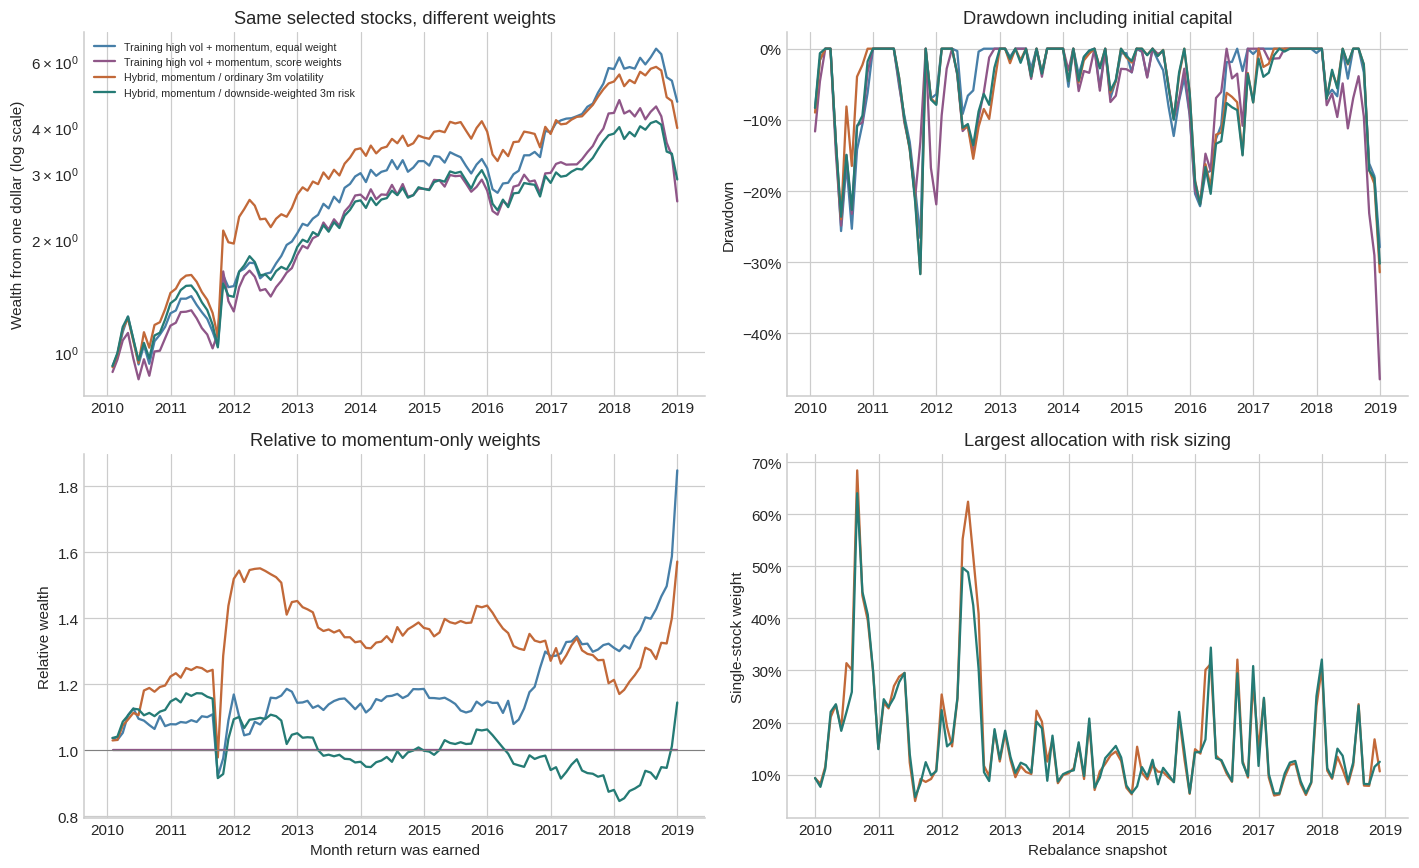

In [4]:
plot_names = ['training_high_vol_momentum_equal',base_name,*SIZING_LABELS]
colors = dict(zip(plot_names,['#477fa8','#8f5688','#c26939','#257b75']))
books = result['all_books']
fig,axes = plt.subplots(2,2,figsize=(13,8))
for name in plot_names:
    book=books[name]
    axes[0,0].plot(book.index,book.wealth,label=labels[name],color=colors[name])
    axes[0,1].plot(book.index,book.drawdown,color=colors[name])
    axes[1,0].plot(book.index,book.wealth/books[base_name].wealth,color=colors[name])
axes[0,0].set_yscale('log')
axes[0,0].set(title='Same selected stocks, different weights',ylabel='Wealth from one dollar (log scale)')
axes[0,0].legend(fontsize=7)
axes[0,1].set(title='Drawdown including initial capital',ylabel='Drawdown')
axes[0,1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1,0].axhline(1,color='gray',lw=0.7)
axes[1,0].set(title='Relative to momentum-only weights',ylabel='Relative wealth',xlabel='Month return was earned')
for name in SIZING_LABELS:
    audit=result['diagnostics'].loc[result['diagnostics'].strategy.eq(name)]
    axes[1,1].plot(audit.date,audit.max_weight,label=labels[name],color=colors[name])
axes[1,1].set(title='Largest allocation with risk sizing',ylabel='Single-stock weight',xlabel='Rebalance snapshot')
axes[1,1].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,'01_downside_comparison')

## 4. Inspect the risk inputs and floor

This first-decision table shows three-month risk estimates alongside the
momentum-only allocation and the two new allocations. Ordinary volatility and
downside-weighted risk use the same dates. Three observations provide little
precision: differences should be interpreted as a rule illustration, not a
claim that a quarter of monthly data establishes a stock's true risk.

In [5]:
example=joined.loc[joined.date.eq('2009-12-31')].merge(risk,on=['date','stock_id'],validate='one_to_one')
example=example.loc[example[base_name].gt(0)].sort_values(base_name,ascending=False)
example.to_csv(OUT/'first_risk_allocation.csv',index=False)
display(example[['stock_id','ordinary_volatility','downside_deviation','downside_weighted_risk',
                 base_name,*SIZING_LABELS]].head(10).round(4))
diag=comparison.set_index('strategy').loc[focus,['avg_names','avg_effective_n','largest_single_weight','avg_one_way_turnover']]
diag.index=diag.index.map(labels)
display(diag.round(4))
floor_summary=result['diagnostics'].groupby('strategy').agg(
    average_selected_floor_hits=('risk_floor_hits','mean'),
    largest_monthly_floor_hits=('risk_floor_hits','max'),
    fallback_months=('parent_fallback_preserved','sum'))
display(floor_summary)

,stock_id,ordinary_volatility,downside_deviation,downside_weighted_risk,training_high_vol_momentum_weighted,hybrid_volatility_3m_sizing,hybrid_downside_3m_sizing
219,221,54.4910,0.0361,54.4910,0.1897,0.0024,0.0026
672,683,19.5258,0.0000,19.5258,0.1520,0.0053,0.0058
107,108,0.5967,0.4179,0.7285,0.0819,0.0933,0.0838
112,113,1.2894,0.7420,1.4877,0.0680,0.0358,0.0340
849,862,0.5251,0.5680,0.7735,0.0639,0.0827,0.0616
160,162,0.7565,0.1800,0.7776,0.0455,0.0409,0.0436
780,792,0.6294,0.5060,0.8076,0.0364,0.0393,0.0336
151,153,0.3579,0.0000,0.3579,0.0175,0.0332,0.0364
668,679,0.6809,0.4263,0.8033,0.0148,0.0148,0.0138
933,949,0.6108,0.3404,0.6992,0.0137,0.0152,0.0146


,avg_names,avg_effective_n,largest_single_weight,avg_one_way_turnover
strategy,,,,
Equal-weight universe,1182.7778,1182.7778,0.0009,0.0289
"Training high-vol universe, equal weight",236.6852,236.6852,0.0046,0.0400
"Training high vol + momentum, equal weight",47.5648,47.5648,0.0227,0.2485
"Training high vol + momentum, score weights",47.5648,24.6962,0.4055,0.2125
"Hybrid, momentum / ordinary 3m volatility",47.5648,19.8355,0.6840,0.3944
"Hybrid, momentum / downside-weighted 3m risk",47.5648,19.9798,0.6401,0.3853


,average_selected_floor_hits,largest_monthly_floor_hits,fallback_months
strategy,,,
hybrid_downside_3m_sizing,0.435185,3,0
hybrid_volatility_3m_sizing,0.527778,4,0


## 5. Save the experiment and compare Sortino consistently

Sortino here uses target return zero and all 108 portfolio-return observations.
A positive month contributes a zero shortfall and remains in the count. The
ratio is not calculated from only the negative observations. Undefined ratios
are recorded as missing, not infinite evidence of investment quality.

All original rules, notebooks, and results are preserved. New output files live
under `outputs/downside/`. The risk penalty and floor were fixed before this
run, with no search over them. Future variants should use chronological training
validation rather than repeated optimization against this already viewed period.

In [6]:
comparison.to_csv(OUT/'strategy_comparison.csv',index=False)
result['monthly'].to_csv(OUT/'new_strategy_monthly_returns.csv',index=False)
result['diagnostics'].to_csv(OUT/'risk_sizing_diagnostics.csv',index=False)
for name,frame in [('risk_signals',risk),('risk_sizing_weights',result['weights'])]:
    frame.to_csv(OUT/(name+'.csv.gz'),index=False,compression={'method':'gzip','mtime':0,'compresslevel':3})
yearly_rows=[]
for name in focus:
    book=books[name]
    annual=(1+book.simple_return).groupby(book.index.year).prod()-1
    yearly_rows.extend({'strategy':name,'year':year,'simple_return':value} for year,value in annual.items())
yearly=pd.DataFrame(yearly_rows)
yearly.to_csv(OUT/'calendar_year_returns.csv',index=False)
annual_table=yearly.pivot(index='year',columns='strategy',values='simple_return').reindex(columns=focus)
annual_table.columns=annual_table.columns.map(labels)
display(annual_table.map(lambda x:f'{x:.1%}'))
files=[ROOT/'mlfactor_long_only_train.csv',ROOT/'mlfactor_long_only_test.csv',
       ROOT/'part0_data_and_benchmark'/'pipeline.py',HERE/'strategies.py',HERE/'hybrid.py',HERE/'downside.py',HERE/'07_downside_rules.md']
manifest={'sources':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in files},
          'specification':spec,'libraries':{'python':platform.python_version(),'numpy':np.__version__,
          'pandas':pd.__version__,'matplotlib':matplotlib.__version__}}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
ix=comparison.set_index('strategy')
new=ix.loc['hybrid_downside_3m_sizing']
control=ix.loc['hybrid_volatility_3m_sizing']
parent=ix.loc[base_name]
lines=['# Three-month downside-weighted sizing: executed findings','',
       'Source: `08_three_month_downside.ipynb`. Rules: `07_downside_rules.md`.','',
       'The new rule retains the hybrid stock selection and divides positive momentum by a three-month downside-weighted risk measure. The ordinary-volatility control uses the same three months, selected stocks, and 1% monthly risk floor.','',
       '## January 2010–December 2018, gross returns','',
       '| Strategy | CAGR | Volatility | Sharpe | Sortino (target 0) | Max drawdown |',
       '| --- | --- | --- | --- | --- | --- |']
for name in focus:
    row=ix.loc[name]
    lines.append(f'| {labels[name]} | {row.cagr:.2%} | {row.annualized_volatility:.2%} | {row.sharpe:.3f} | {row.sortino:.3f} | {row.max_drawdown:.2%} |')
lines.extend(['',
    f'- Adding the downside term versus ordinary 3m risk sizing changes CAGR by {100*(new.cagr-control.cagr):+.2f} percentage points, Sharpe by {new.sharpe-control.sharpe:+.3f}, and Sortino by {new.sortino-control.sortino:+.3f}.',
    f'- Versus the prior momentum-only allocation, CAGR changes by {100*(new.cagr-parent.cagr):+.2f} percentage points. This comparison changes both inverse-risk sizing and the floor, not just downside sensitivity.',
    f'- The new rule averages {new.avg_names:.1f} held names and {new.avg_effective_n:.1f} effective holdings. Largest single-stock weight: {new.largest_single_weight:.2%}; average one-way turnover: {new.avg_one_way_turnover:.2%}.','',
    '## What the names mean','',
    'The earlier rolling risk estimate used twelve monthly observations. This new sizing estimate uses three. The frozen training volatility screen and twelve-month momentum remain unchanged. Volatility is a nonnegative magnitude; negative returns receive an extra penalty. The custom measure is not itself Sharpe or Sortino.','',
    'Sharpe is mean excess return divided by its standard deviation. Sortino is mean return above a target divided by root-mean-square shortfalls below that target. Positive observations remain in the denominator count with zero shortfall. Both ratios here use the monthly sqrt(12) convention. See the sources in the notebook for definitions.','',
    'Three observations give a noisy risk estimate. This already examined historical period cannot establish an optimal risk measure, window, floor, or penalty. No parameter search, caps, costs, or return clipping were added. Earlier project files and outputs are preserved.'])
(HERE/'09_downside_findings.md').write_text('\n'.join(lines)+'\n')
display(Markdown(f'**New rule: CAGR {new.cagr:.2%}, Sharpe {new.sharpe:.3f}, Sortino {new.sortino:.3f}, maximum drawdown {new.max_drawdown:.2%}.**'))

strategy,Equal-weight universe,"Training high-vol universe, equal weight","Training high vol + momentum, equal weight","Training high vol + momentum, score weights","Hybrid, momentum / ordinary 3m volatility","Hybrid, momentum / downside-weighted 3m risk"
year,,,,,,
2010,25.8%,40.5%,26.9%,17.6%,43.9%,35.0%
2011,0.4%,-4.2%,18.2%,9.1%,35.5%,4.1%
2012,20.9%,27.2%,38.5%,41.5%,35.2%,36.0%
2013,34.9%,45.9%,44.8%,45.1%,33.0%,33.2%
2014,12.2%,12.5%,7.7%,3.7%,6.8%,7.3%
2015,-4.6%,-4.2%,-4.2%,-1.1%,3.8%,5.3%
2016,26.7%,34.6%,24.8%,11.5%,-1.4%,-1.4%
2017,19.7%,25.1%,47.5%,44.7%,38.1%,35.4%
2018,-9.5%,-3.6%,-18.3%,-42.0%,-24.9%,-24.6%


**New rule: CAGR 12.53%, Sharpe 0.559, Sortino 1.043, maximum drawdown -31.67%.**